# Music Instrument Classification - Stems

## Setup

In [45]:
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
import numpy as np
import os
from sklearn.model_selection import train_test_split
import glob
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix

Utility function:

In [46]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None, title=''):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
        title: Title of the plot
    """
    
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title(title)
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

Custom classes definition and indexing:

In [47]:
# Final categories - Essential for interpreting the numeric indices
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices - Useful if you need to convert names to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

Loading and splitting data:

In [48]:
# Load pre-processed data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

Loaded data: (68879, 96, 130)


Showing the instruments distribution in the MedleyDB dataset:


Class distribution in the complete dataset:
    other_percussion:               9085 samples (13.2%)
    electric_bass:               6781 samples (9.8%)
    drum_set:               6300 samples (9.1%)
    piano:               5604 samples (8.1%)
    other_bowed_strings:               4946 samples (7.2%)
    clean_electric_guitar:               4790 samples (7.0%)
    synthesizer:               4711 samples (6.8%)
    other_plucked_strings:               3635 samples (5.3%)
    fx_and_processed:               3452 samples (5.0%)
    male_vocals:               3180 samples (4.6%)
    violin:               3010 samples (4.4%)
    distorted_electric_guitar:               2475 samples (3.6%)
    acoustic_guitar:               2452 samples (3.6%)
    female_singer:               2190 samples (3.2%)
    woodwinds:               1860 samples (2.7%)
    vocalists:               1565 samples (2.3%)
    reed_instruments:               1460 samples (2.1%)
    brass:               1383 samples (2

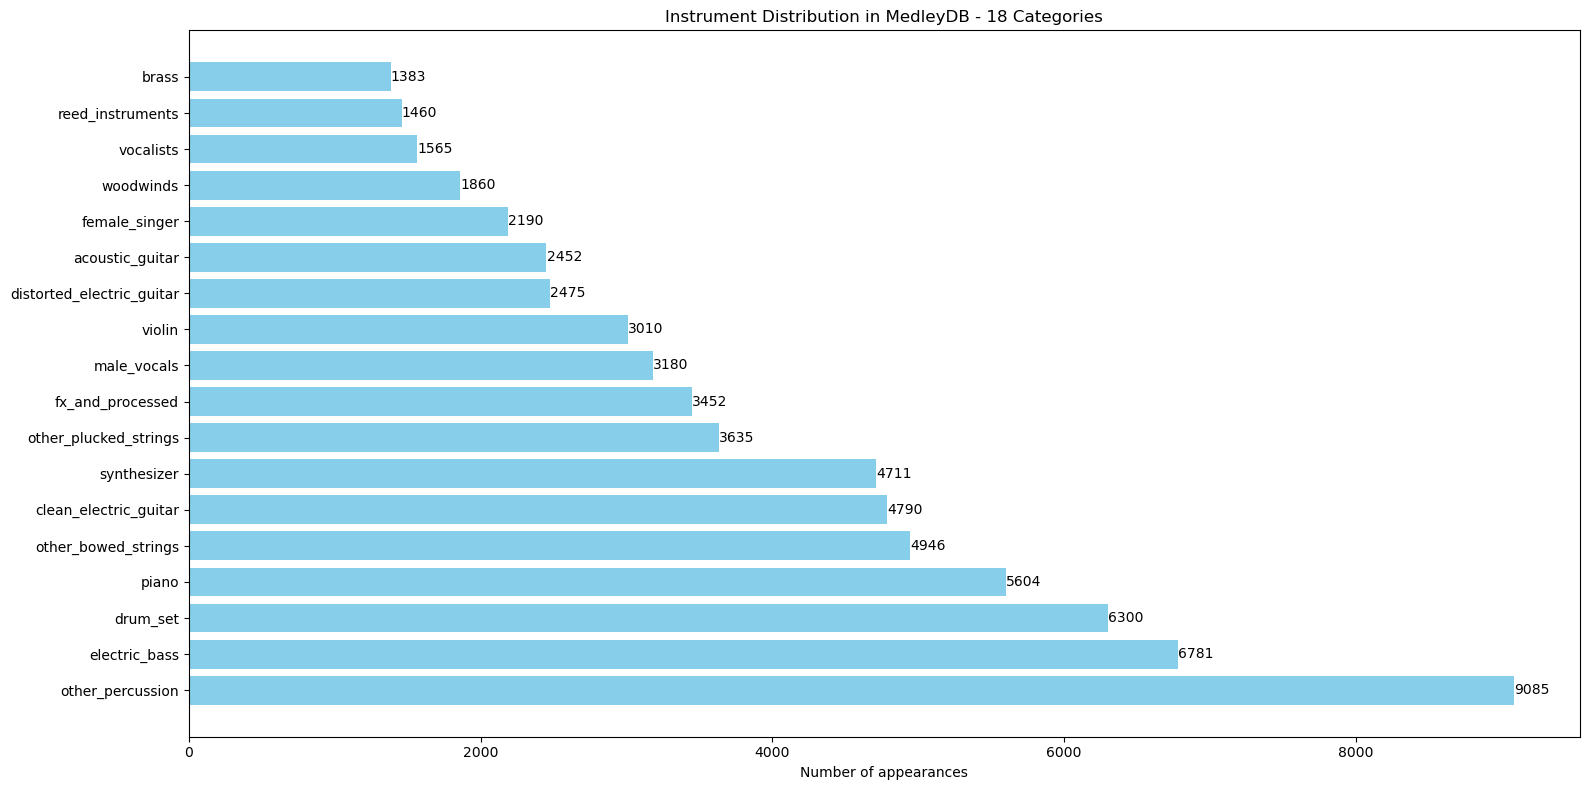


Dataset dimensions:
    Full data:                  (68879, 96, 130)
    Total number of samples:    68879
    Number of categories:       18


In [49]:
# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y, return_counts=True)

# Create a dictionary in the format {instrument: frequency}
instrument_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = instrument_categories[idx]
    instrument_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the complete dataset:")
for category, count in sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"    {category}:               {count} samples ({count/len(y)*100:.1f}%)")

# Plot histogram of instrument distribution
plot_instrument_histogram(instrument_counts, top_n=len(instrument_categories), title='Instrument Distribution in MedleyDB - 18 Categories')

print(f"\nDataset dimensions:")
print(f"    Full data:                  {X.shape}")
print(f"    Total number of samples:    {len(y)}")
print(f"    Number of categories:       {len(instrument_categories)}")

Defining inverse mapping and alphabetically ordered labels:

In [50]:
# Create inverse mapping from index to category name
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

## Model 1

The biggest model in terms of trainable parameters:

| Layer Type           | Details                                                        |
|:---------------------|:--------------------------------------------------------------|
| Input                | Input shape: (96, 130, 1)                                      |
| Conv2D               | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **64**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **128**, Kernel: 3x3, Activation: relu, Padding: same     |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Flatten              |                                                               |
| Dense                | Units: **128**, Activation: relu                                  |
| Dropout              | Rate: 0.3                                                     |
| Dense                | Units: 18, Activation: softmax                                |

In [51]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_16 (Conv2D)          (None, 96, 130, 32)       320       
                                                                 
 batch_normalization_16 (Bat  (None, 96, 130, 32)      128       
 chNormalization)                                                
                                                                 
 max_pooling2d_16 (MaxPoolin  (None, 48, 65, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_17 (Conv2D)          (None, 48, 65, 64)        18496     
                                                                 
 batch_normalization_17 (Bat  (None, 48, 65, 64)       256       
 chNormalization)                                                
                                                      

Training the model and saving history and weights in the files `training_model_stem.log` and `best_model_stem.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [52]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_stem.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=100)

model_name = 'best_model_stem.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_stem.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=100)\n\nmodel_name = 'best_model_stem.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\nmodel.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),\n    loss='sparse_categorical_crossentropy',\n    metrics=['accuracy']\n)\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=1000,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 1 history:

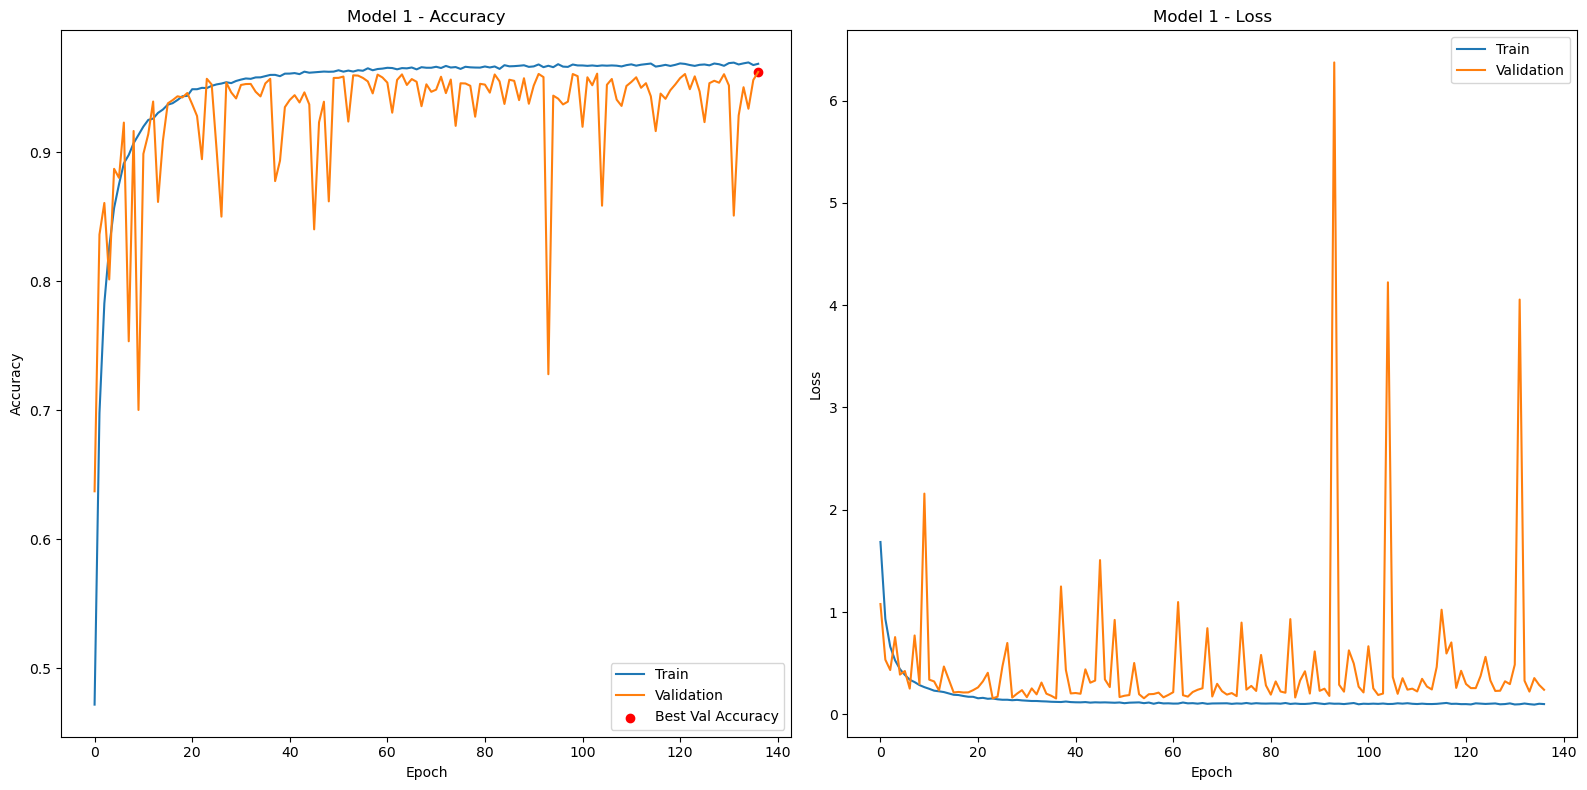

In [53]:
# History plot
log_df = pd.read_csv('training_model_stem.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 1 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 1 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 1 confusion matrixes:

216/216 [==============================] - 1s 4ms/step


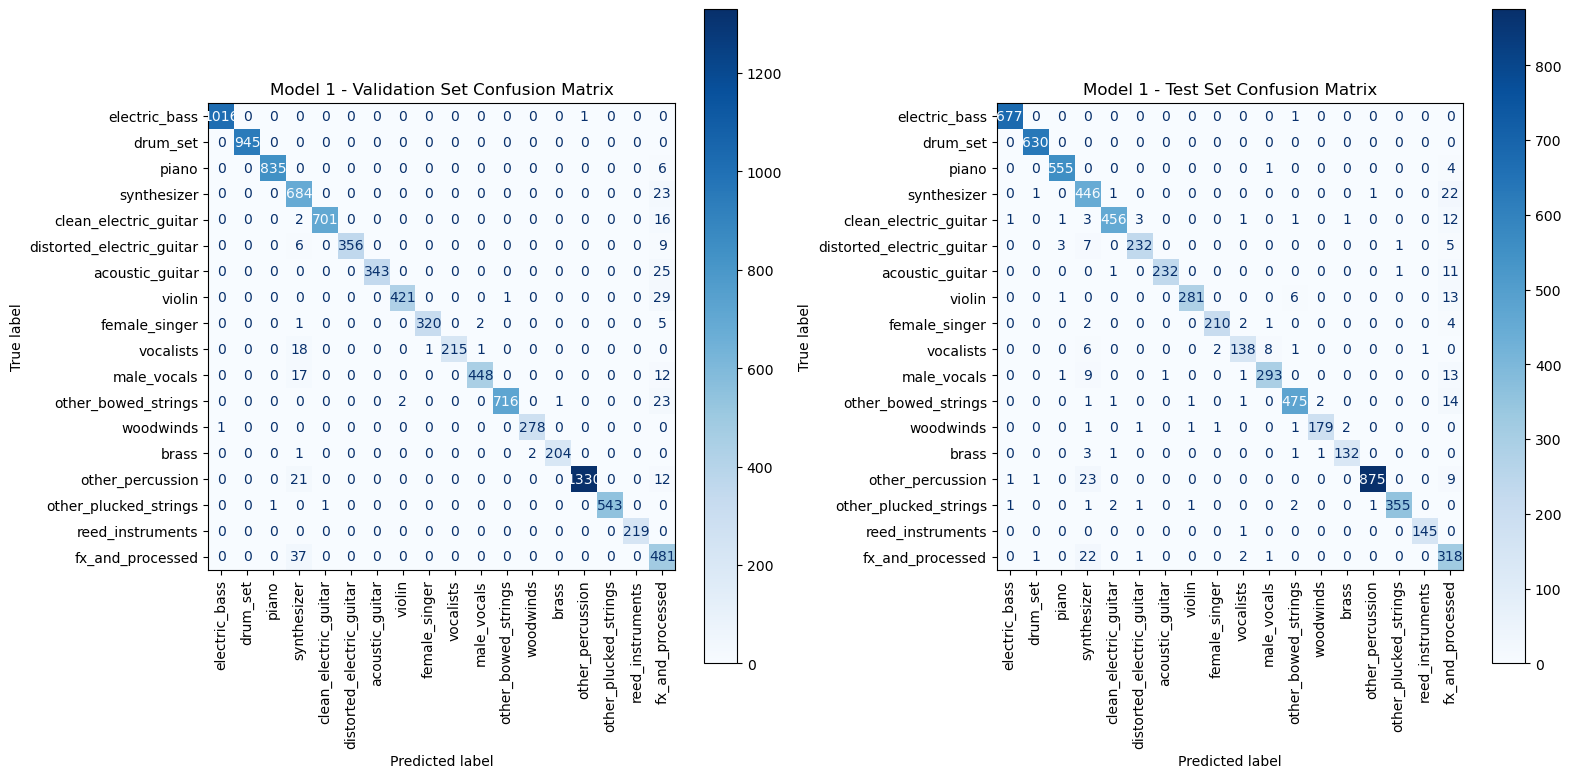

In [54]:
# Load the best model weights
model.load_weights('best_model_stem.h5')

# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Get ordered category labels
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Plot
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 1 - Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 1 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 1 classification reports:

In [55]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1017
           1       1.00      1.00      1.00       945
           2       1.00      0.99      1.00       841
           3       0.87      0.97      0.92       707
           4       1.00      0.97      0.99       719
           5       1.00      0.96      0.98       371
           6       1.00      0.93      0.96       368
           7       1.00      0.93      0.96       451
           8       1.00      0.98      0.99       328
           9       1.00      0.91      0.96       235
          10       0.99      0.94      0.97       477
          11       1.00      0.96      0.98       742
          12       0.99      1.00      0.99       279
          13       1.00      0.99      0.99       207
          14       1.00      0.98      0.99      1363
          15       1.00      1.00      1.00       545
          16       1.00      1.00      1.00       219
          17       0.75    

## Model 2

Data splitting and normalization:

In [56]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# Normalize the data
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (68879, 96, 130)


Reducing the model architecture size:

| Layer Type           | Details                                                        |
|:---------------------|:--------------------------------------------------------------|
| Input                | Input shape: (96, 130, 1)                                      |
| Conv2D               | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **64**, Kernel: 3x3, Activation: relu, Padding: same     |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Flatten              |                                                               |
| Dense                | Units: **64**, Activation: relu                                   |
| Dropout              | Rate: 0.3                                                     |
| Dense                | Units: 18, Activation: softmax                                |

In [57]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_19 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_19 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_19 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_20 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_20 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                      

Training the model and saving history and weights in the files `training_model_stem_small_cqt.log` and `best_model_stem_small_cqt.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [58]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_small_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_stem_small_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_stem_small_cqt.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=50)\n\nmodel_name = 'best_model_stem_small_cqt.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\nmodel.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),\n    loss='sparse_categorical_crossentropy',\n    metrics=['accuracy']\n)\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=300,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 2 history:

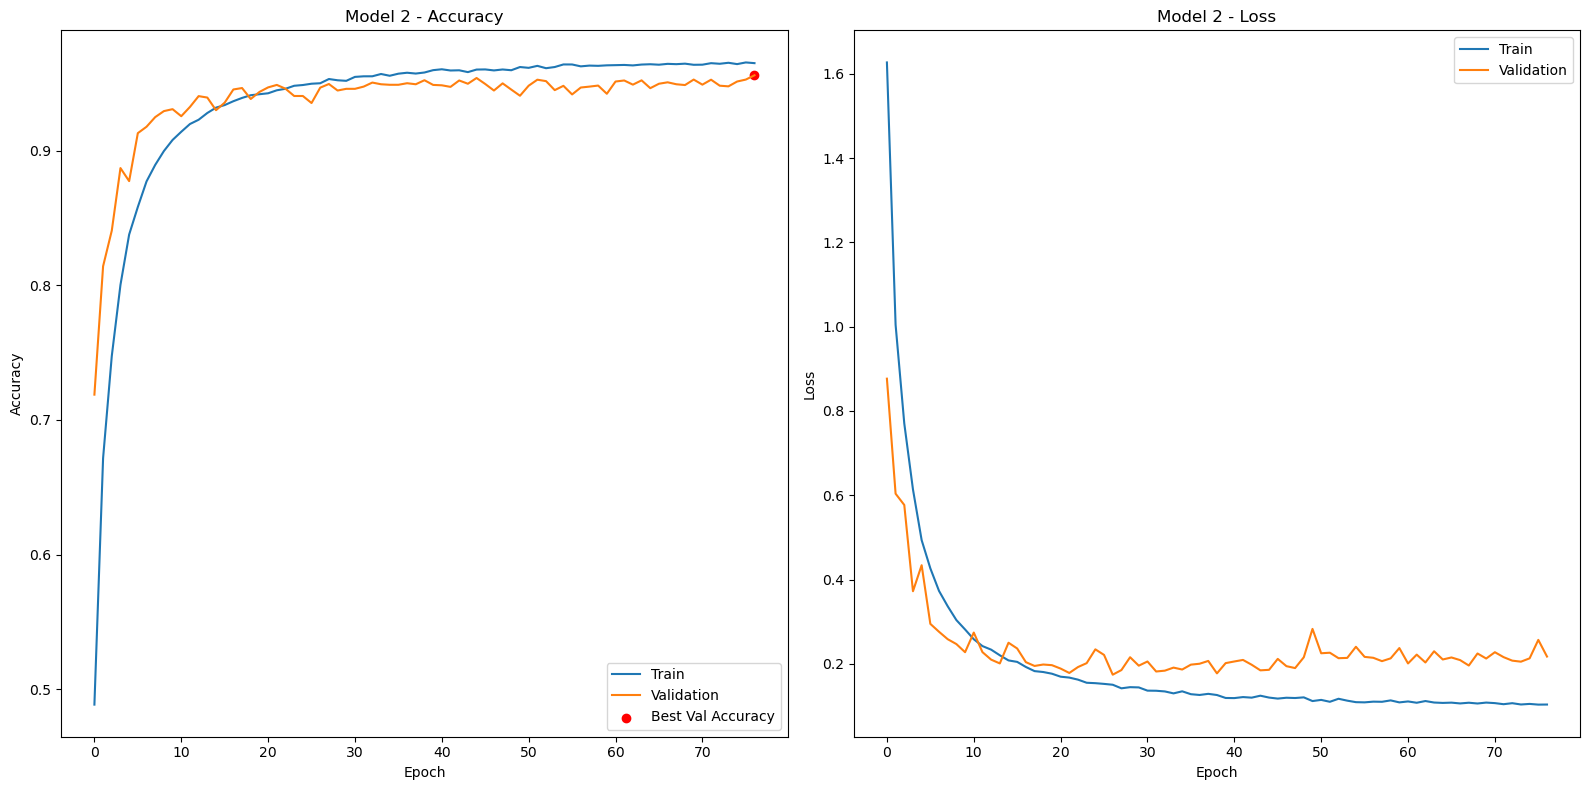

In [59]:
# History plot
log_df = pd.read_csv('training_model_stem_small_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 2 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 2 confusion matrixes:

216/216 [==============================] - 1s 2ms/step


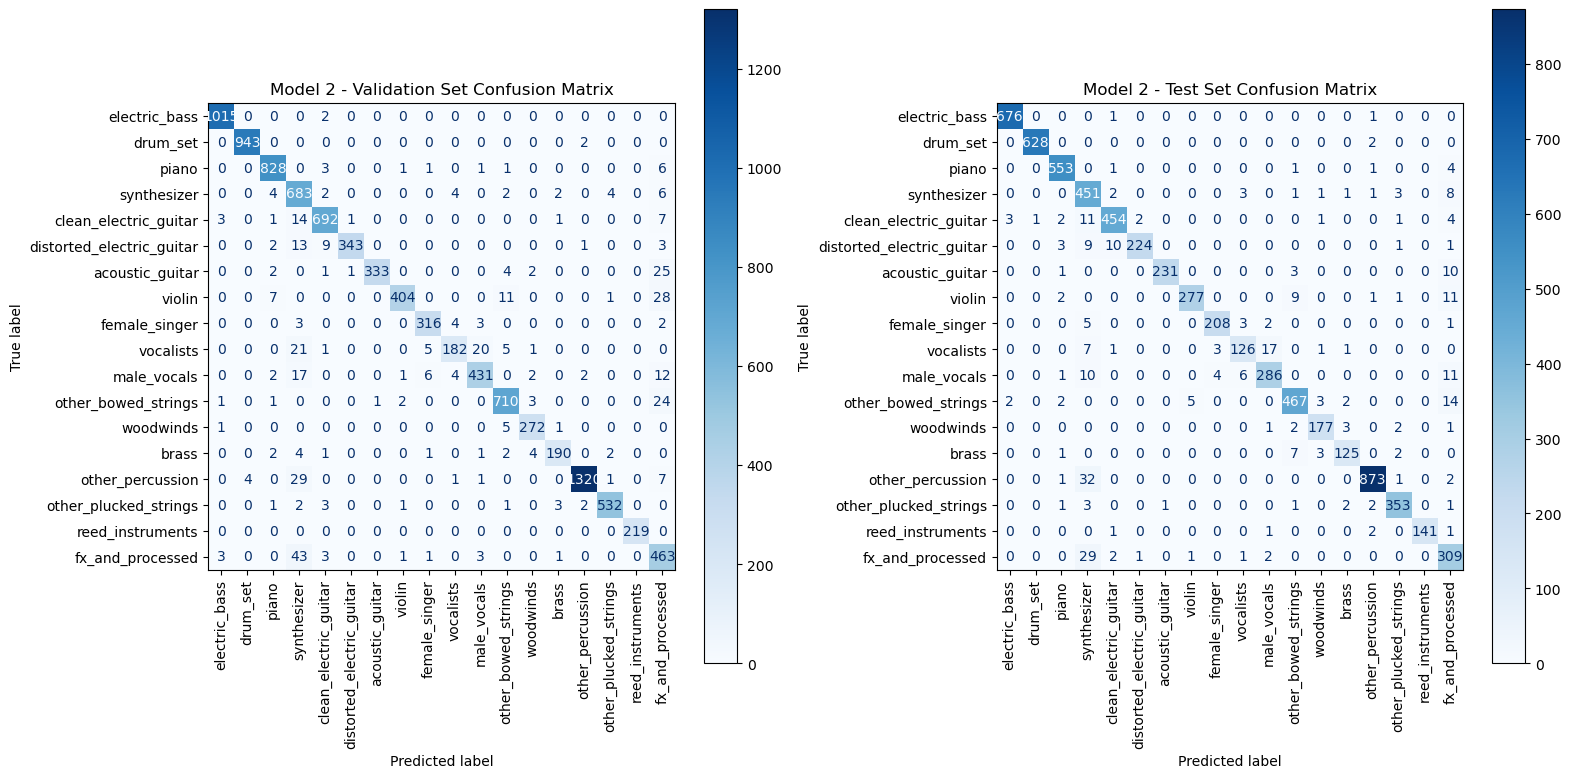

In [60]:
model.load_weights('best_model_stem_small_cqt.h5')

# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 2 - Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 2 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 2 classification reports:

In [61]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.99      1.00      1.00      1017
                 drum_set       1.00      1.00      1.00       945
                    piano       0.97      0.98      0.98       841
              synthesizer       0.82      0.97      0.89       707
    clean_electric_guitar       0.97      0.96      0.96       719
distorted_electric_guitar       0.99      0.92      0.96       371
          acoustic_guitar       1.00      0.90      0.95       368
                   violin       0.99      0.90      0.94       451
            female_singer       0.96      0.96      0.96       328
                vocalists       0.93      0.77      0.85       235
              male_vocals       0.94      0.90      0.92       477
      other_bowed_strings       0.96      0.96      0.96       742
                woodwinds       0.96      0.97      0.97       279
                    brass       0.96      0.92      0.94     

## Model 3

Reducing the output layer to 32 and overall model size:

| Layer Type           | Details                                                        |
|:---------------------|:--------------------------------------------------------------|
| Input                | Input shape: (96, 130, 1)                                      |
| Conv2D               | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **64**, Kernel: 3x3, Activation: relu, Padding: same     |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Flatten              |                                                               |
| Dense                | Units: **32**, Activation: relu                                   |
| Dropout              | Rate: 0.3                                                     |
| Dense                | Units: 18, Activation: softmax                                |

In [62]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax') 
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_22 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_22 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_22 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_23 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_23 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                      

Training the model and saving history and weights in the files `training_model_stem_smaller_cqt.log` and `best_model_stem_smaller_cqt.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [63]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_smaller_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_smaller_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_stem_smaller_cqt.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=80)\n\nmodel_name = 'best_model_stem_smaller_cqt.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\nmodel.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),\n    loss='sparse_categorical_crossentropy',\n    metrics=['accuracy']\n)\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=500,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 3 history:

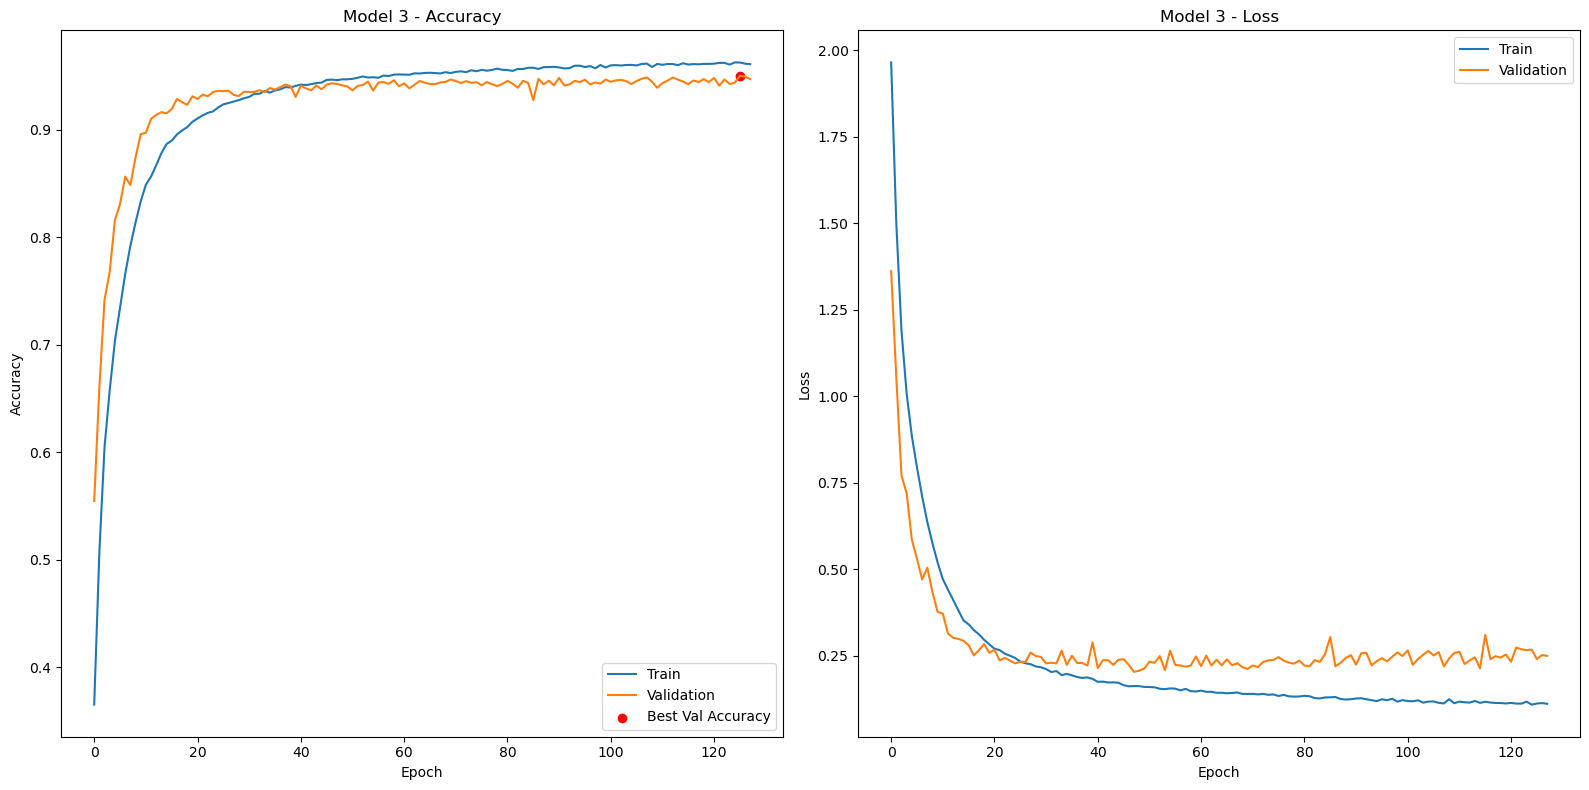

In [64]:
# History plot
log_df = pd.read_csv('training_model_stem_smaller_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 3 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 3 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 3 confusion matrixes:

216/216 [==============================] - 1s 2ms/step


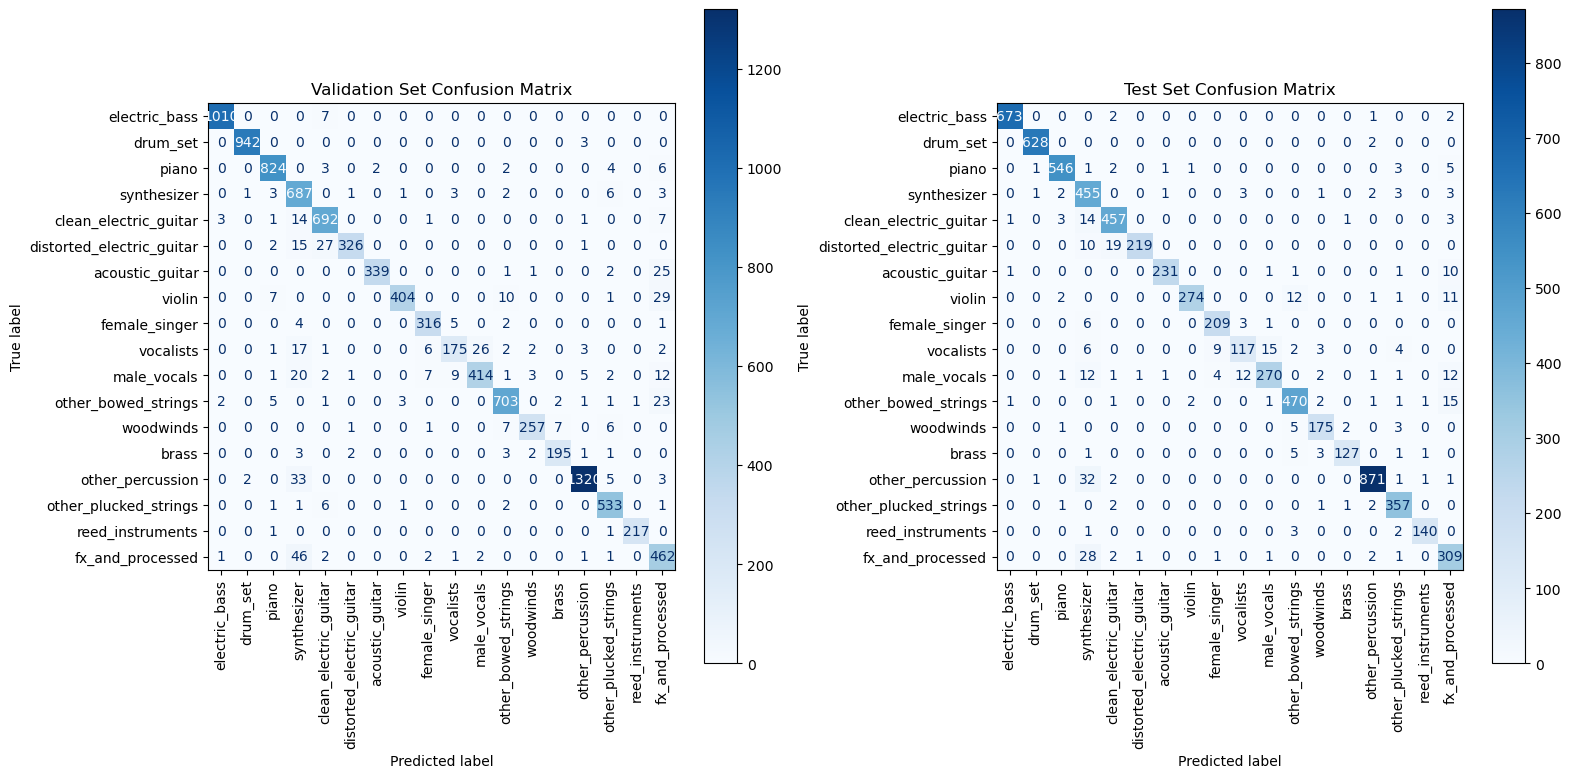

In [65]:
model.load_weights('best_model_stem_smaller_cqt.h5')

# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 3 classification reports:

In [66]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.99      0.99      0.99      1017
                 drum_set       1.00      1.00      1.00       945
                    piano       0.97      0.98      0.98       841
              synthesizer       0.82      0.97      0.89       707
    clean_electric_guitar       0.93      0.96      0.95       719
distorted_electric_guitar       0.98      0.88      0.93       371
          acoustic_guitar       0.99      0.92      0.96       368
                   violin       0.99      0.90      0.94       451
            female_singer       0.95      0.96      0.96       328
                vocalists       0.91      0.74      0.82       235
              male_vocals       0.94      0.87      0.90       477
      other_bowed_strings       0.96      0.95      0.95       742
                woodwinds       0.97      0.92      0.94       279
                    brass       0.96      0.94      0.95     

## Model 4

Replacing Flatten with GlobalAveragePooling2D and reducing model size by removing a layer:

| Layer Type               | Details                                                        |
|:-------------------------|:--------------------------------------------------------------|
| Input                    | Input shape: (96, 130, 1)                                      |
| Conv2D                   | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization       |                                                               |
| MaxPooling2D             | Pool size: 2x2                                                |
| Conv2D                   | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization       |                                                               |
| MaxPooling2D             | Pool size: 2x2                                                |
| GlobalAveragePooling2D   |                                                               |
| Dense                    | Units: **64**, Activation: relu                               |
| Dropout                  | Rate: 0.3                                                     |
| Dense                    | Units: 18, Activation: softmax                     |


In [67]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')  
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_25 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_25 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_25 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_26 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_26 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                      

Training the model and saving history and weights in the files `training_model_stem_GAP_cqt.log` and `best_model_stem_GAP_cqt.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [68]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_GAP_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_GAP_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_stem_GAP_cqt.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=80)\n\nmodel_name = 'best_model_stem_GAP_cqt.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\nmodel.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),\n    loss='sparse_categorical_crossentropy',\n    metrics=['accuracy']\n)\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=500,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 4 history:

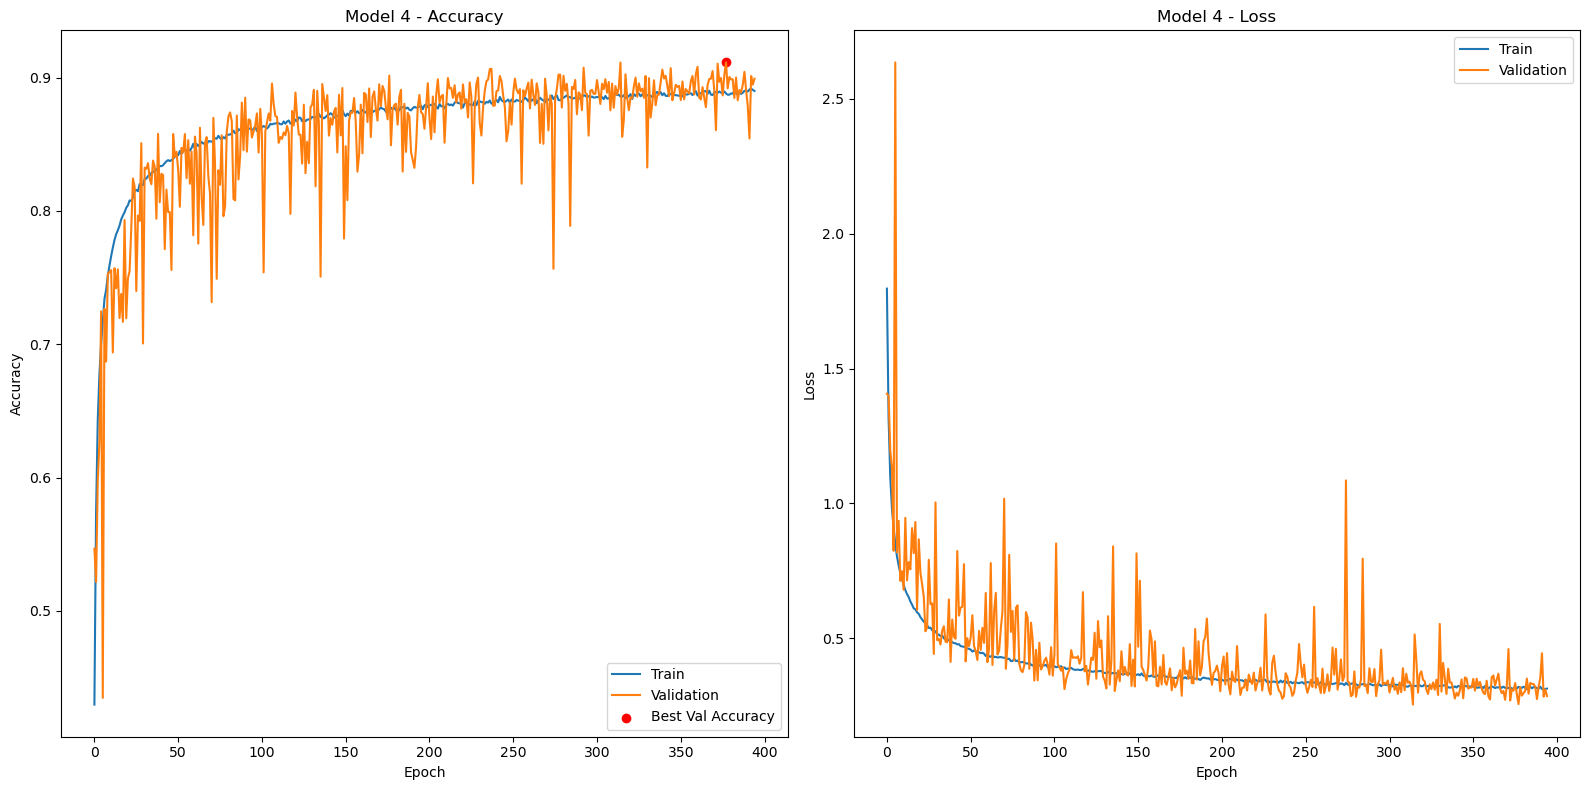

In [69]:
# History plot
log_df = pd.read_csv('training_model_stem_GAP_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 4 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 4 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 4 confusion matrixes:

216/216 [==============================] - 0s 2ms/step


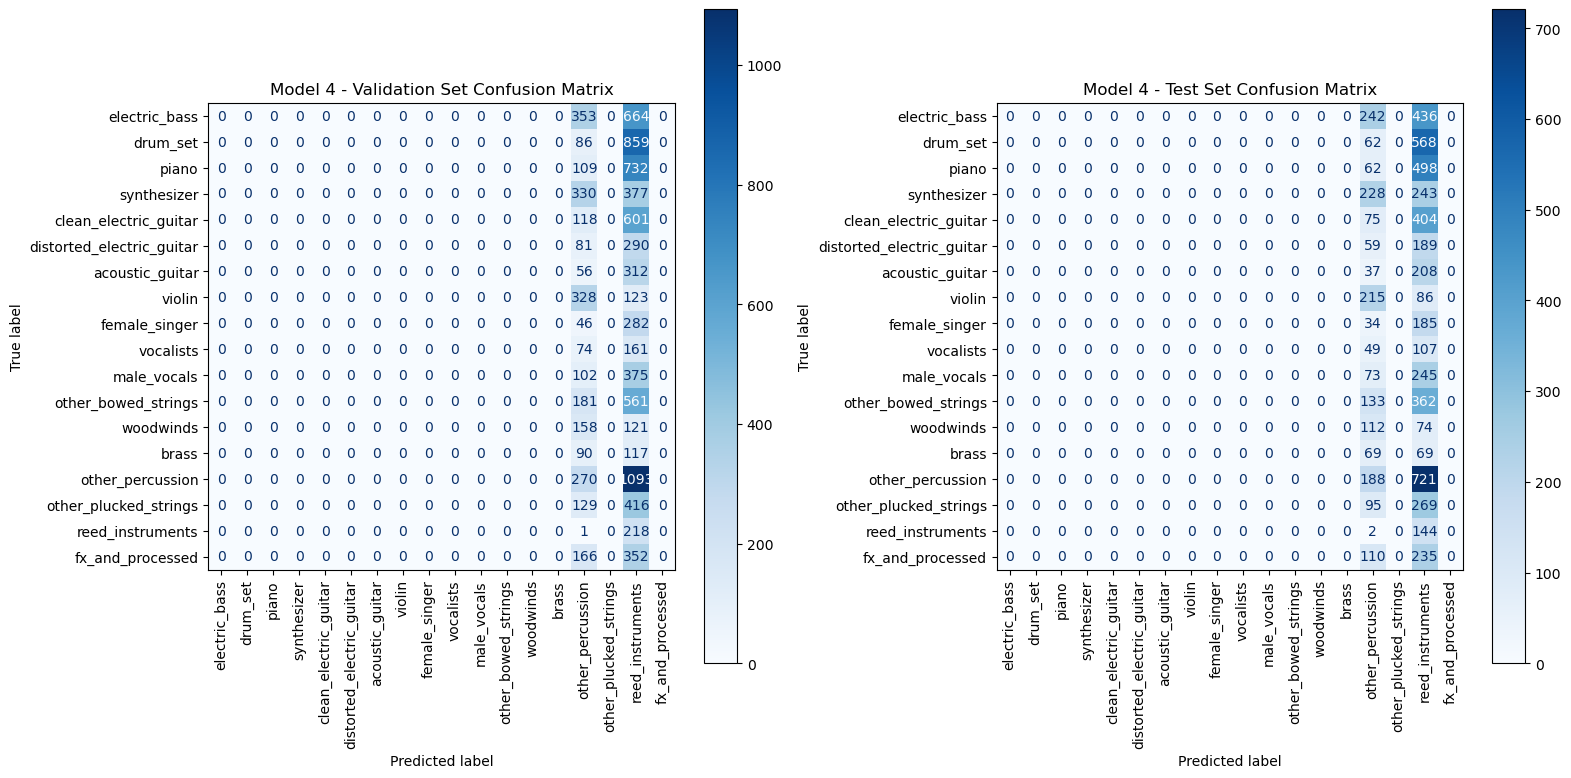

In [70]:
model.load_weights('best_model_stem_GAP_cqt.h5')

# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 4 - Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 4 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 4 classification reports:

In [71]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.00      0.00      0.00      1017
                 drum_set       0.00      0.00      0.00       945
                    piano       0.00      0.00      0.00       841
              synthesizer       0.00      0.00      0.00       707
    clean_electric_guitar       0.00      0.00      0.00       719
distorted_electric_guitar       0.00      0.00      0.00       371
          acoustic_guitar       0.00      0.00      0.00       368
                   violin       0.00      0.00      0.00       451
            female_singer       0.00      0.00      0.00       328
                vocalists       0.00      0.00      0.00       235
              male_vocals       0.00      0.00      0.00       477
      other_bowed_strings       0.00      0.00      0.00       742
                woodwinds       0.00      0.00      0.00       279
                    brass       0.00      0.00      0.00     

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r

## Model 5

Changing features from cqt to mel: data splitting and normalization.

In [72]:
# Load pre-processed data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_mel.npy'))
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# Normalize the data
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (68879, 96, 130)


Using the same architecture of model 4:

| Layer Type               | Details                                                        |
|:-------------------------|:--------------------------------------------------------------|
| Input                    | Input shape: (96, 130, 1)                                      |
| Conv2D                   | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization       |                                                               |
| MaxPooling2D             | Pool size: 2x2                                                |
| Conv2D                   | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization       |                                                               |
| MaxPooling2D             | Pool size: 2x2                                                |
| GlobalAveragePooling2D   |                                                               |
| Dense                    | Units: **64**, Activation: relu                               |
| Dropout                  | Rate: 0.3                                                     |
| Dense                    | Units: 18, Activation: softmax                     |

In [73]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')  
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_27 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_27 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_27 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_28 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_28 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                     

Training the model and saving history and weights in the files `training_model_stem_GAP_mel.log` and `best_model_stem_GAP_mel.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [74]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_GAP_mel.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_GAP_mel.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_stem_GAP_mel.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=80)\n\nmodel_name = 'best_model_stem_GAP_mel.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\nmodel.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),\n    loss='sparse_categorical_crossentropy',\n    metrics=['accuracy']\n)\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=500,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 5 history:

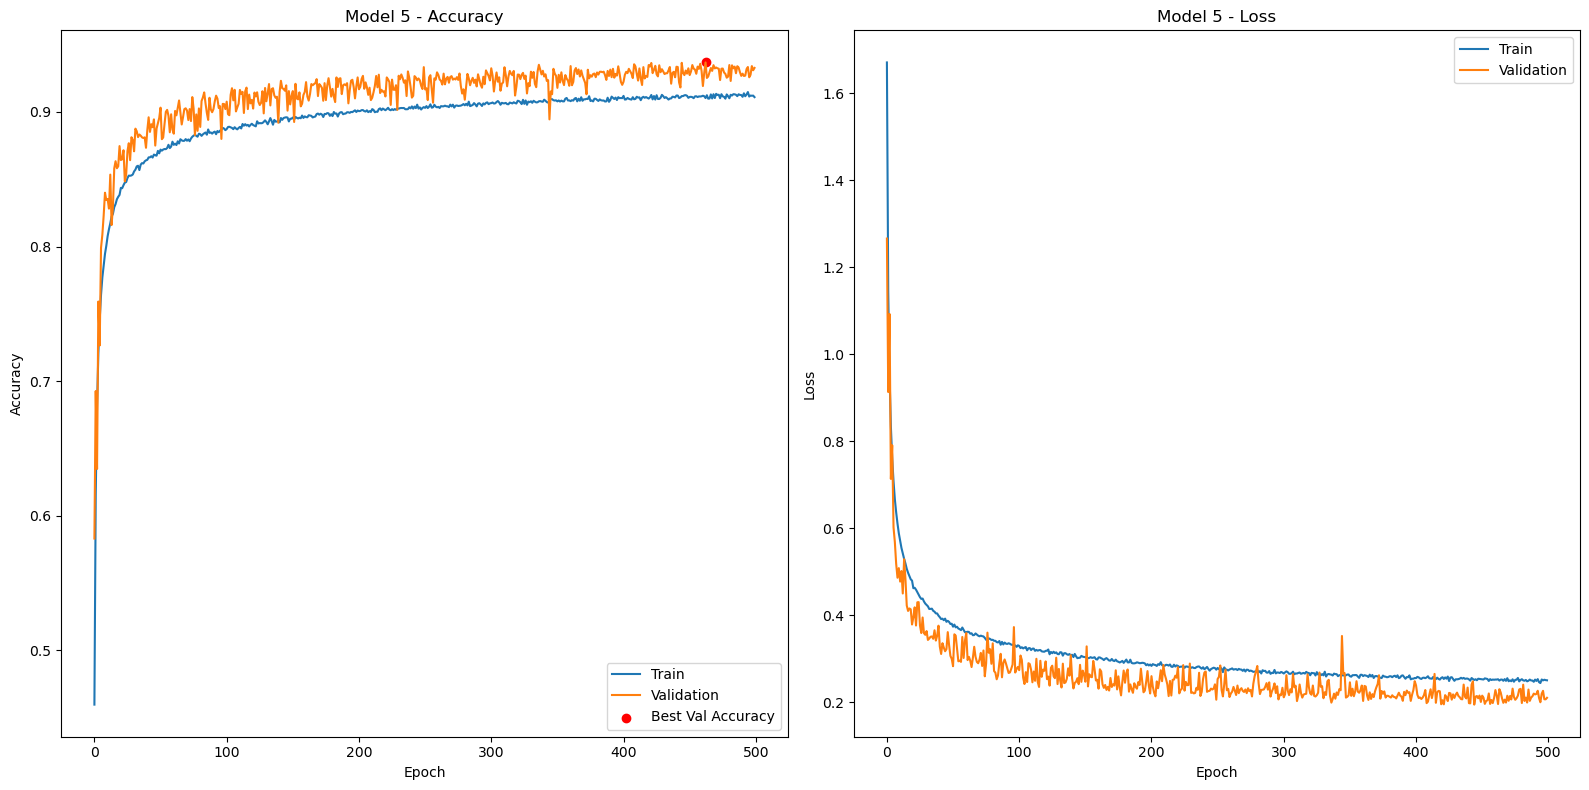

In [75]:
# History plot
log_df = pd.read_csv('training_model_stem_GAP_mel.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 5 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 5 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 5 confusion matrixes:

216/216 [==============================] - 0s 2ms/step


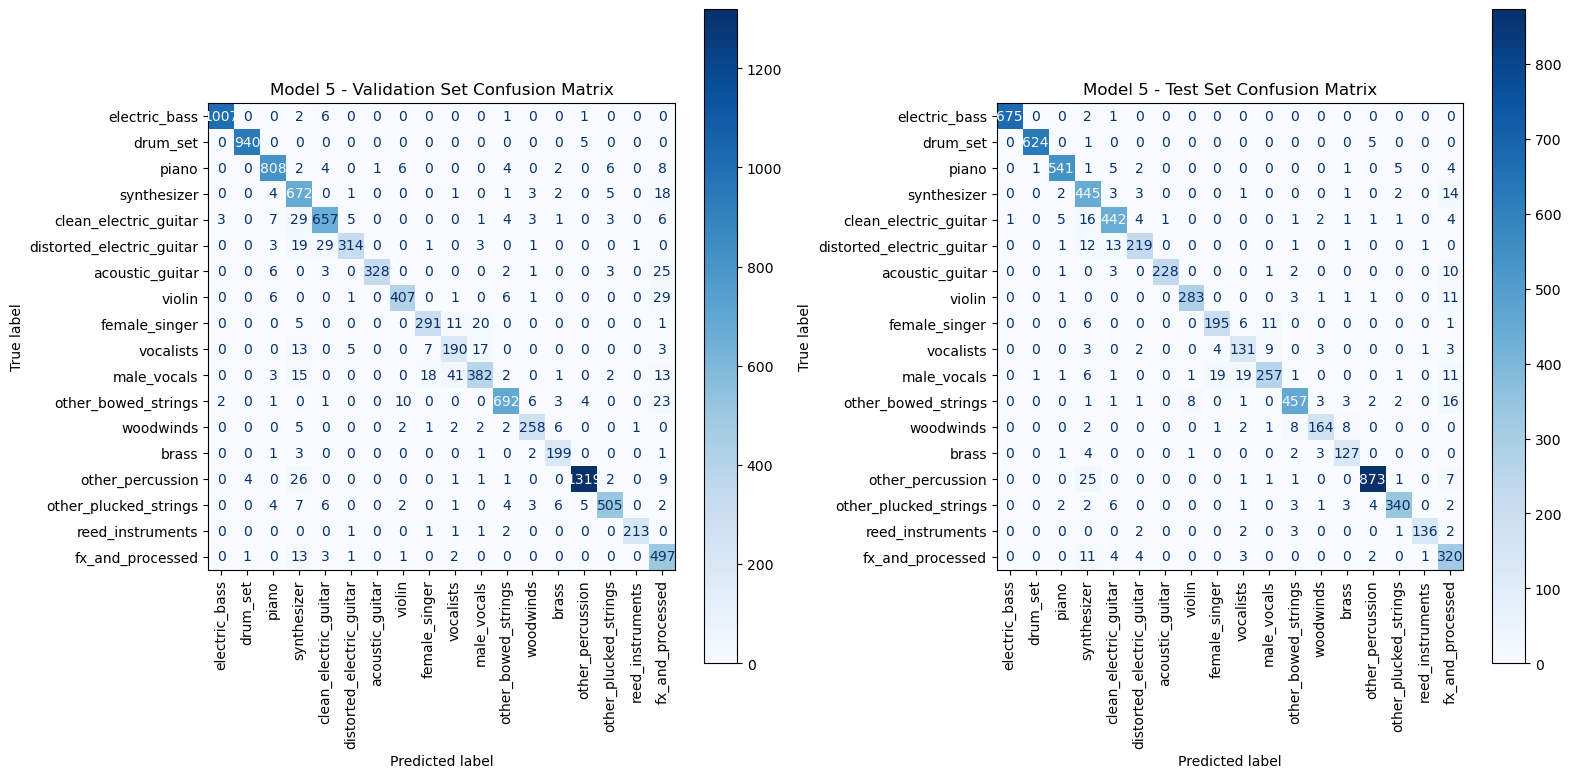

In [76]:
model.load_weights('best_model_stem_GAP_mel.h5')

# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 5 - Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 5 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 5 classification reports:

In [77]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       1.00      0.99      0.99      1017
                 drum_set       0.99      0.99      0.99       945
                    piano       0.96      0.96      0.96       841
              synthesizer       0.83      0.95      0.89       707
    clean_electric_guitar       0.93      0.91      0.92       719
distorted_electric_guitar       0.96      0.85      0.90       371
          acoustic_guitar       1.00      0.89      0.94       368
                   violin       0.95      0.90      0.93       451
            female_singer       0.91      0.89      0.90       328
                vocalists       0.76      0.81      0.78       235
              male_vocals       0.89      0.80      0.84       477
      other_bowed_strings       0.96      0.93      0.95       742
                woodwinds       0.93      0.92      0.93       279
                    brass       0.90      0.96      0.93     

## Classes reduction

In this section, we study the classification capabilities cleaning ambiguous classes and merging too-similar classes.

Loading data and removing unwanted classes:

In [78]:
# Load data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_mel.npy'))
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Remove classes 3 ('synthesizer') and 17 ('fx_and_processed')
classes_to_remove = [3, 17]

# Create a mask to filter out the unwanted classes
mask = ~np.isin(y, classes_to_remove)
X_filtered = X[mask]
y_filtered = y[mask]

# Create inverse mapping from index to category name
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Remove the unwanted classes from the ordered labels
for idx in sorted(classes_to_remove, reverse=True):
    del ordered_labels[idx]

# Create a mapping from old class indices to new class indices
old_to_new = {}
new_idx = 0
for i in range(18):  # original class range
    if i not in classes_to_remove:
        old_to_new[i] = new_idx
        new_idx += 1

# Apply the mapping to y_filtered
y_filtered = np.array([old_to_new[old_label] for old_label in y_filtered])

Merging similar classes

In [79]:
# Classes to merge (by index after cleaning)
classes_to_merge = [7, 8, 9]
new_class_name = 'voices'

# Update labels and names
# Step 1: Create mapping from original indices to class names (already cleaned)
idx_to_category = {i: label for i, label in enumerate(ordered_labels)}

# Step 2: Create new name for merged classes
# Keep only one representative name
merged_label_set = set(classes_to_merge)
merged_name = new_class_name

# Step 3: Reassign merged labels in y_filtered
y_merged = y_filtered.copy()
for idx in merged_label_set:
    y_merged[y_merged == idx] = classes_to_merge[0]  # Assign all to the first for simplicity

# Step 4: Remove redundant indices in reverse order to avoid breaking the order
# (except the first of the merge, which is where all will fall)
for idx in sorted(classes_to_merge[1:], reverse=True):
    del idx_to_category[idx]

# Step 5: Change the name of the index that is kept
idx_to_category[classes_to_merge[0]] = merged_name

# Step 6: Reorder indices
old_to_new = {}
new_labels = []
new_idx = 0
for old_idx in sorted(idx_to_category.keys()):
    old_to_new[old_idx] = new_idx
    new_labels.append(idx_to_category[old_idx])
    new_idx += 1

# Step 7: Apply the new mapping to the labels
y_final = np.array([old_to_new[old_label] for old_label in y_merged])
X_final = X_filtered  # No change

# Final list of classes
ordered_labels = new_labels

# Verification
print("Final labels:    ", ordered_labels)
print("Shape X_final:   ", X_final.shape)
print("Shape y_final:   ", np.shape(y_final))

Final labels:     ['electric_bass', 'drum_set', 'piano', 'clean_electric_guitar', 'distorted_electric_guitar', 'acoustic_guitar', 'violin', 'voices', 'other_bowed_strings', 'woodwinds', 'brass', 'other_percussion', 'other_plucked_strings', 'reed_instruments']
Shape X_final:    (60716, 96, 130)
Shape y_final:    (60716,)


Showing the new instruments distribution in the MedleyDB dataset, using 14 classes instead of 18:


Class distribution in the filtered dataset:
    other_percussion:               9085 samples (15.0%)
    voices:               6935 samples (11.4%)
    electric_bass:               6781 samples (11.2%)
    drum_set:               6300 samples (10.4%)
    piano:               5604 samples (9.2%)
    other_bowed_strings:               4946 samples (8.1%)
    clean_electric_guitar:               4790 samples (7.9%)
    other_plucked_strings:               3635 samples (6.0%)
    violin:               3010 samples (5.0%)
    distorted_electric_guitar:               2475 samples (4.1%)
    acoustic_guitar:               2452 samples (4.0%)
    woodwinds:               1860 samples (3.1%)
    reed_instruments:               1460 samples (2.4%)
    brass:               1383 samples (2.3%)


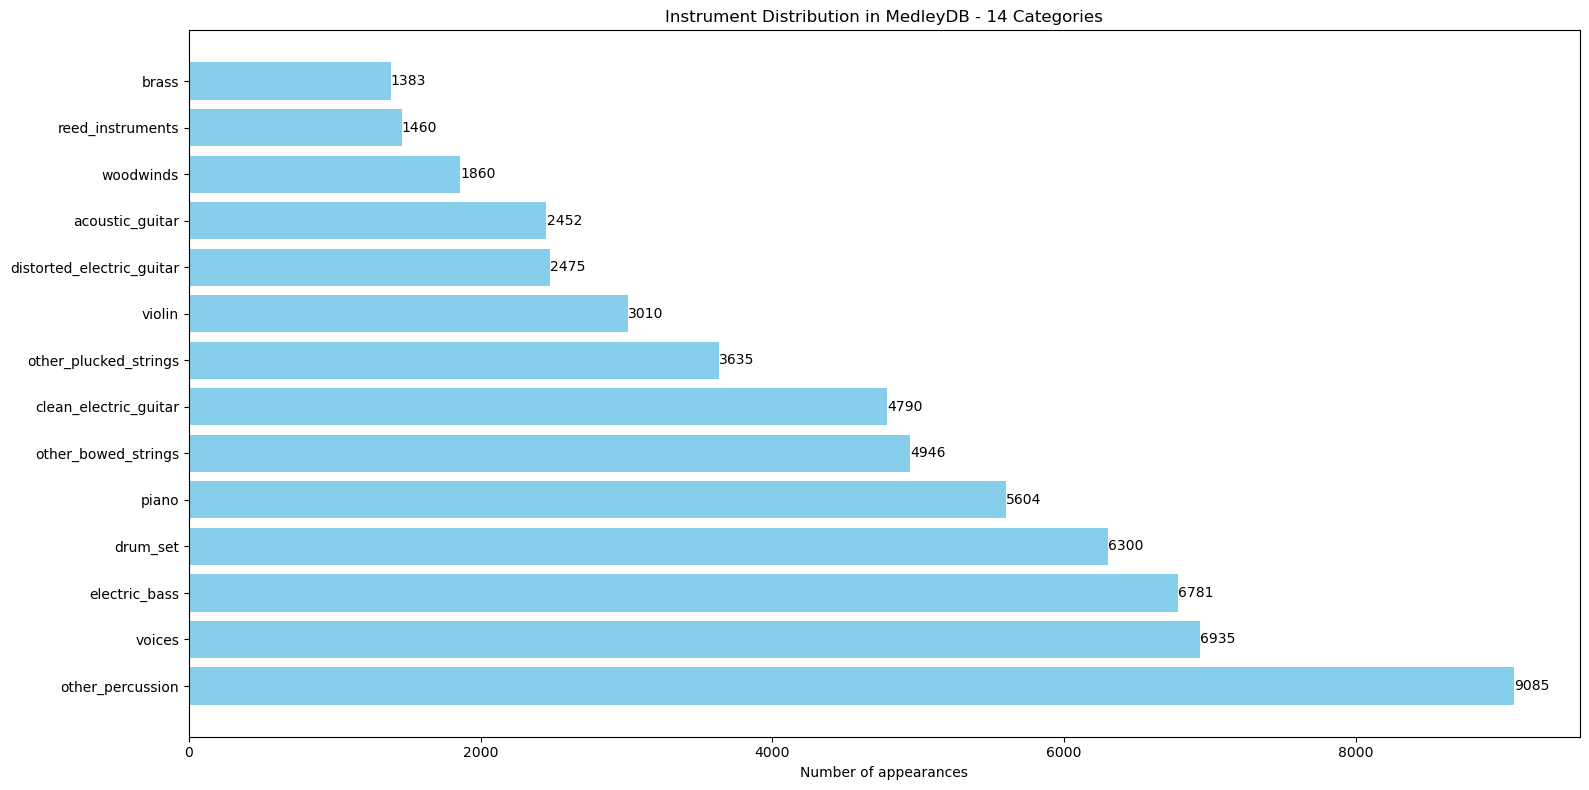


Dataset dimensions:
    Filtered data:                (60716, 96, 130)
    Total number of samples:      60716
    Number of categories:         14


In [80]:
# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y_final, return_counts=True)

# Create a dictionary in the format {category_name: count}
category_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = ordered_labels[idx]
    category_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the filtered dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"    {category}:               {count} samples ({count / len(y_filtered) * 100:.1f}%)")

# Plot histogram of instrument distribution
plot_instrument_histogram(category_counts, top_n=len(ordered_labels), title='Instrument Distribution in MedleyDB - 14 Categories')

# Dataset summary
print(f"\nDataset dimensions:")
print(f"    Filtered data:                {X_filtered.shape}")
print(f"    Total number of samples:      {len(y_filtered)}")
print(f"    Number of categories:         {len(ordered_labels)}")

## Model 6

Data splitting and normalization:

In [81]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X_final, y_final, test_size=0.1, random_state=42, stratify=y_final
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X_final.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# Normalize the data
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (60716, 96, 130)


We take the same architecture of model 3, changing Flatten into GlobalAveragePooling2D:

| Layer Type           | Details                                                        |
|:---------------------|:--------------------------------------------------------------|
| Input                | Input shape: (96, 130, 1)                                      |
| Conv2D               | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same      |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **64**, Kernel: 3x3, Activation: relu, Padding: same     |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| GlobalAveragePooling2D              |                                                               |
| Dense                | Units: **32**, Activation: relu                                   |
| Dropout              | Rate: 0.3                                                     |
| Dense                | Units: 14, Activation: softmax                                |

In [82]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')  
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_29 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_29 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_29 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_30 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_30 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                     

Training the model and saving history and weights in the files `training_model_stem_small_GAP_mel.log` and `best_model_stem_small_GAP_mel.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [84]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_small_GAP_mel.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_small_GAP_mel.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_stem_small_GAP_mel.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=80)\n\nmodel_name = 'best_model_stem_small_GAP_mel.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\nmodel.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),\n    loss='sparse_categorical_crossentropy',\n    metrics=['accuracy']\n)\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=500,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 6 history:

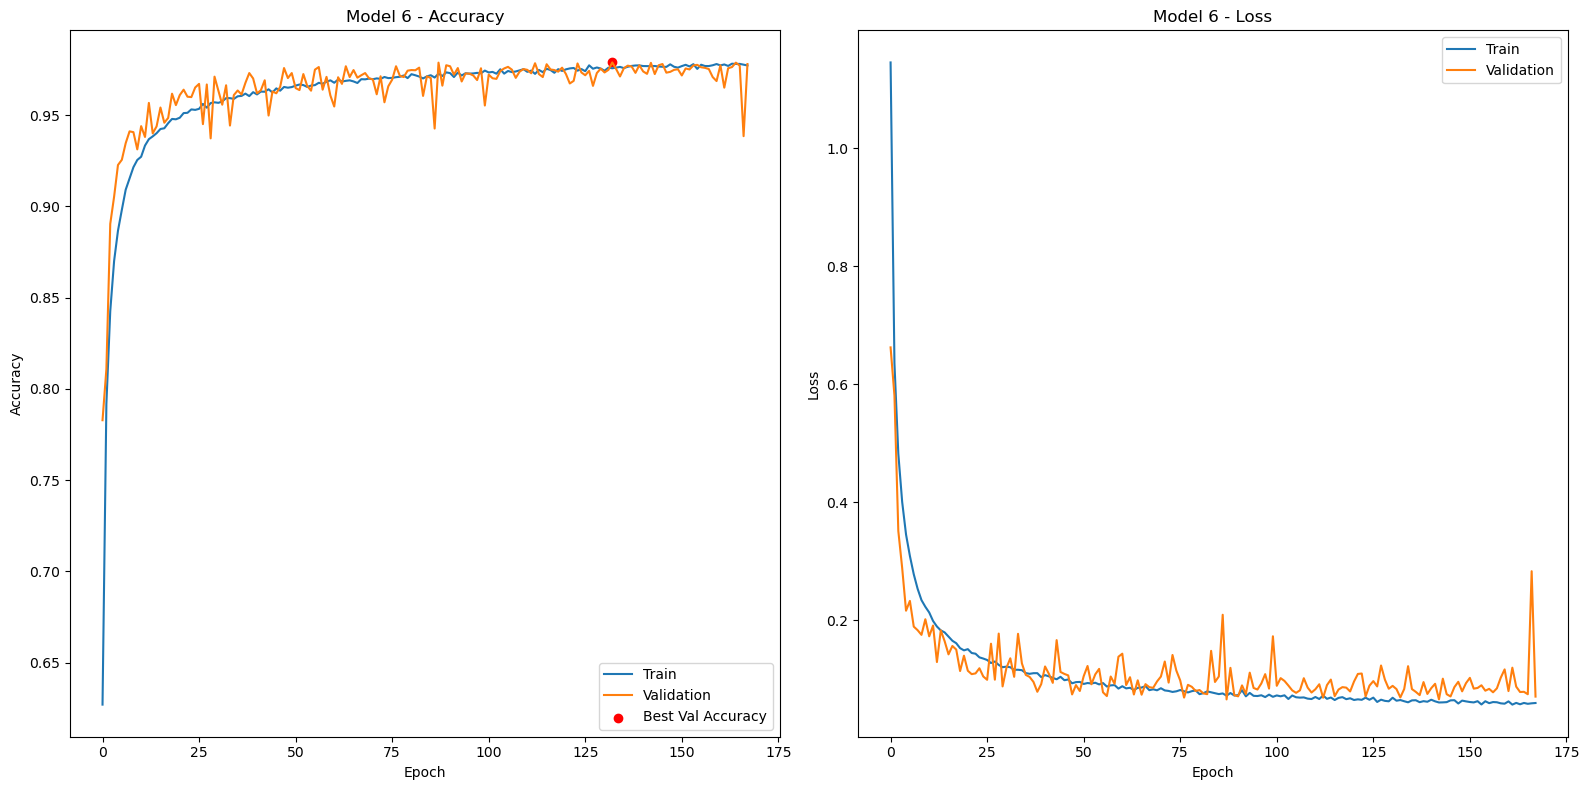

In [85]:
# History plot
log_df = pd.read_csv('training_model_stem_small_GAP_mel.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 6 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 6 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 6 confusion matrixes:

190/190 [==============================] - 0s 2ms/step


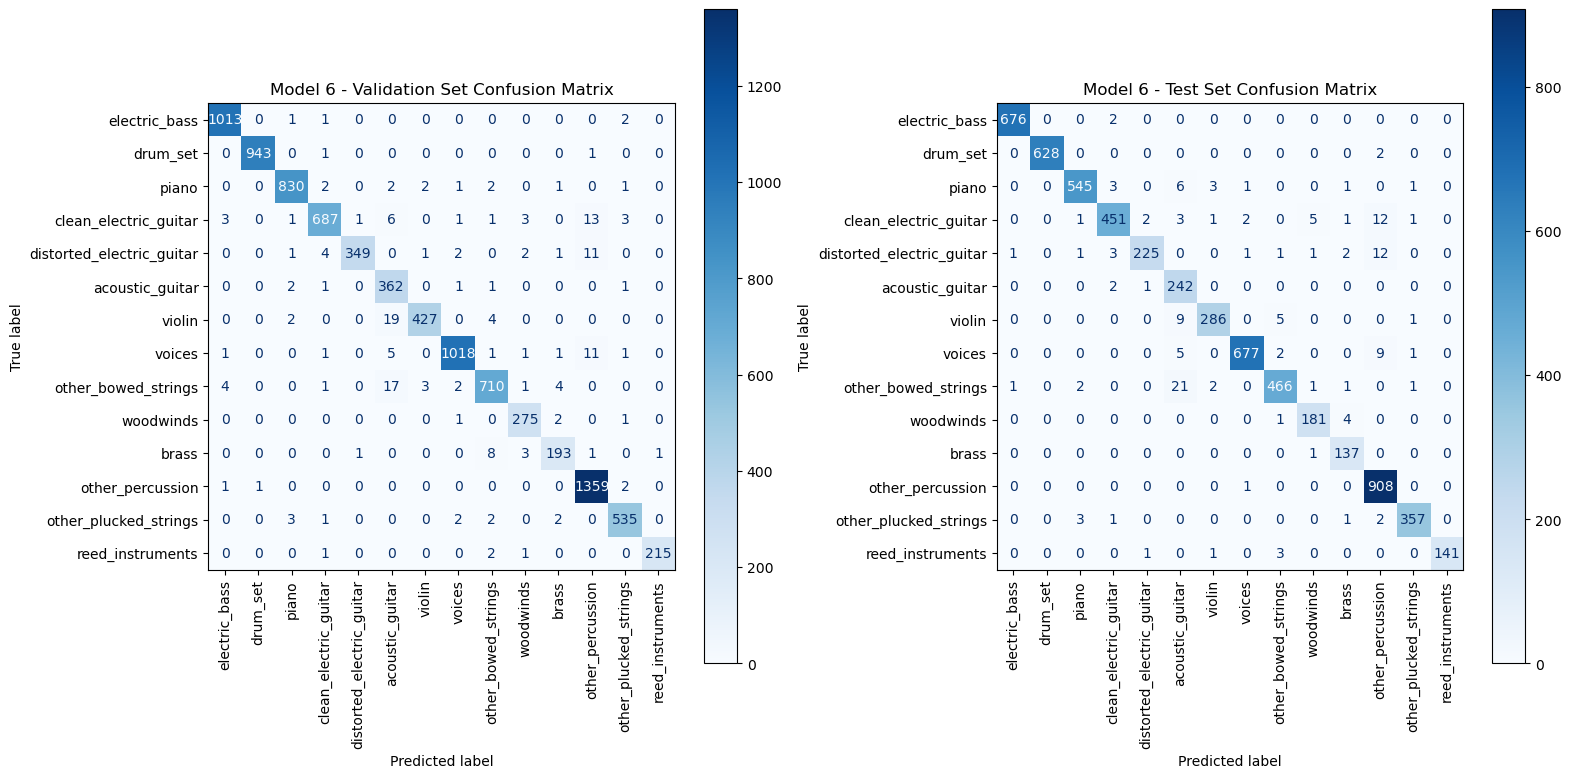

In [86]:
model.load_weights('best_model_stem_small_GAP_mel.h5')

# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 6 - Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Model 6 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Showing model 6 classification reports:

In [87]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.99      1.00      0.99      1017
                 drum_set       1.00      1.00      1.00       945
                    piano       0.99      0.99      0.99       841
    clean_electric_guitar       0.98      0.96      0.97       719
distorted_electric_guitar       0.99      0.94      0.97       371
          acoustic_guitar       0.88      0.98      0.93       368
                   violin       0.99      0.94      0.96       452
                   voices       0.99      0.98      0.98      1040
      other_bowed_strings       0.97      0.96      0.96       742
                woodwinds       0.96      0.99      0.97       279
                    brass       0.95      0.93      0.94       207
         other_percussion       0.97      1.00      0.99      1363
    other_plucked_strings       0.98      0.98      0.98       545
         reed_instruments       1.00      0.98      0.99     